Dataset:
   Order_ID   Product     Category      Region  Quantity  Unit_Price  \
0      1001    Laptop  Electronics     Chennai         5       50000   
1      1002     Mouse  Accessories     Chennai        20         500   
2      1003  Keyboard  Accessories     Madurai        15        1000   
3      1004   Monitor  Electronics  Coimbatore         8       15000   
4      1005    Laptop  Electronics   Bengaluru         3       50000   

   Discount  Customer_Rating     Sales  
0      0.05              4.5  237500.0  
1      0.10              4.2    9000.0  
2      0.05              4.0   14250.0  
3      0.08              4.6  110400.0  
4      0.12              4.8  132000.0  

Dataset Shape: (50, 9)


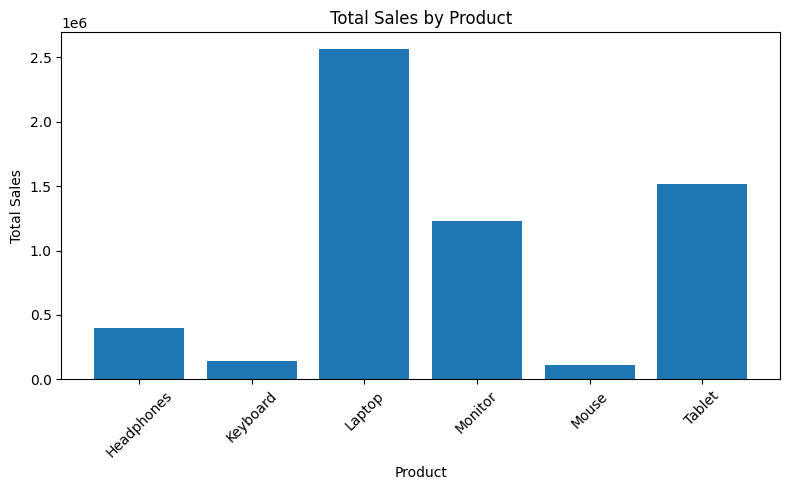

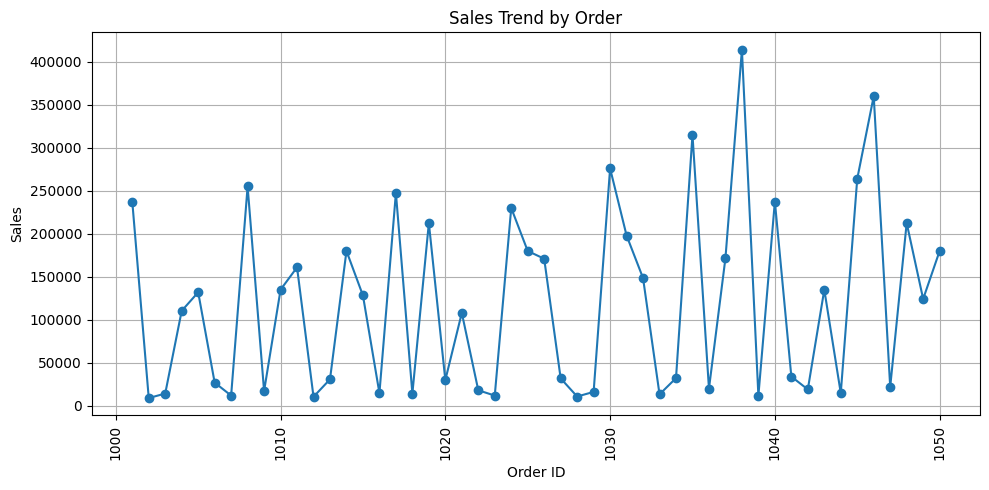

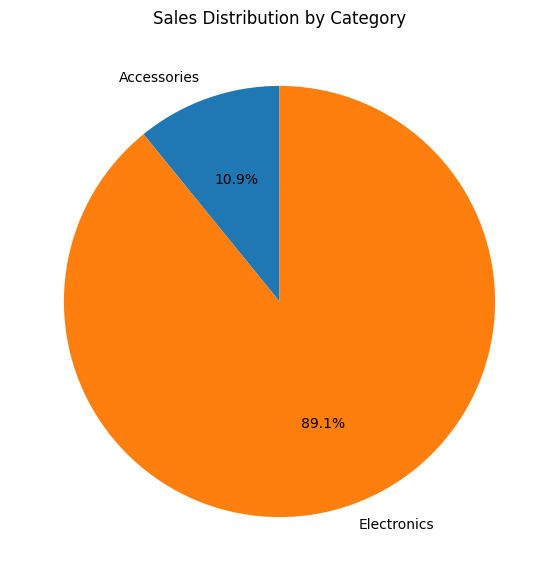

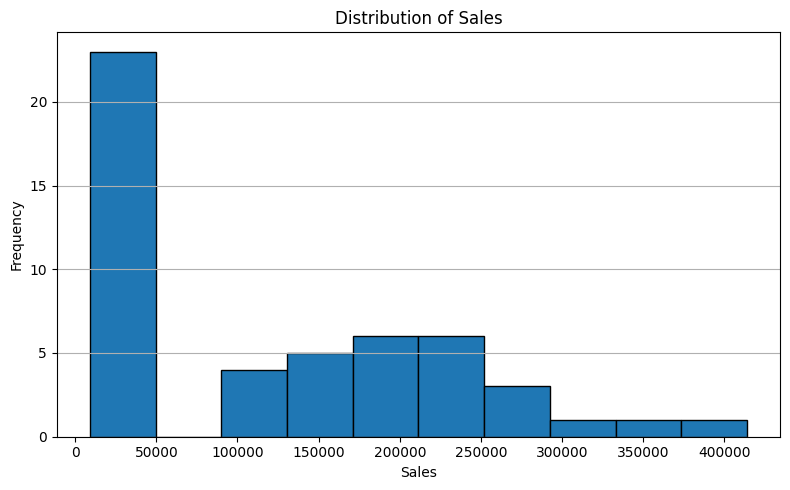

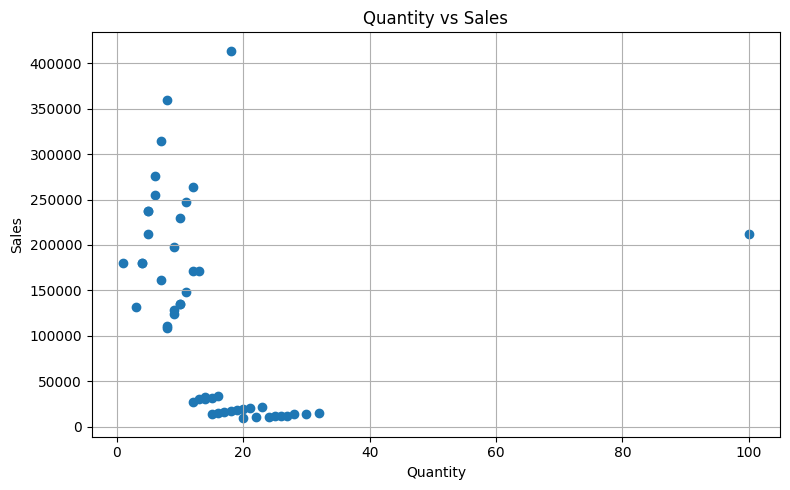

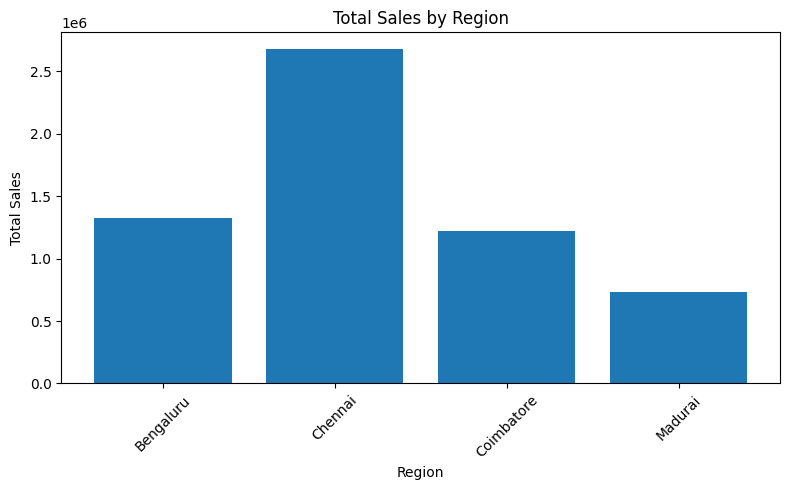

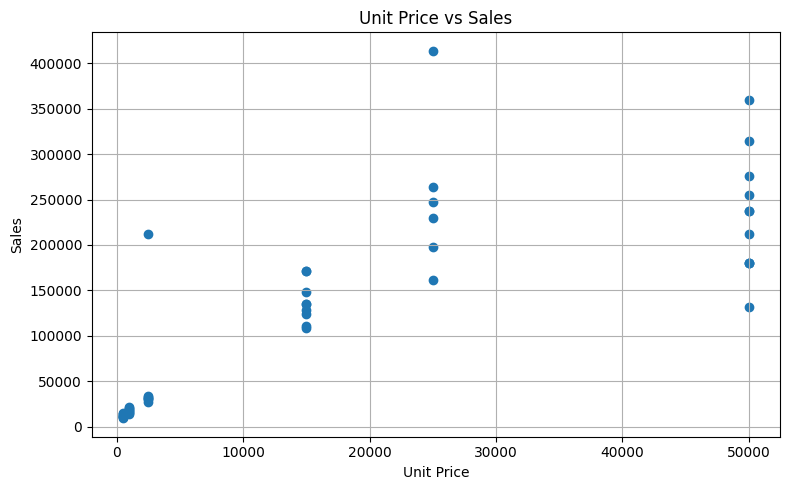

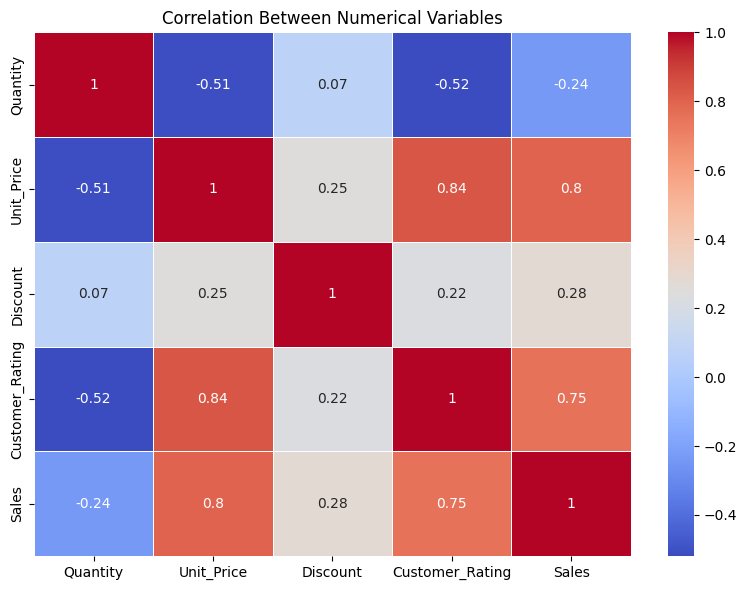

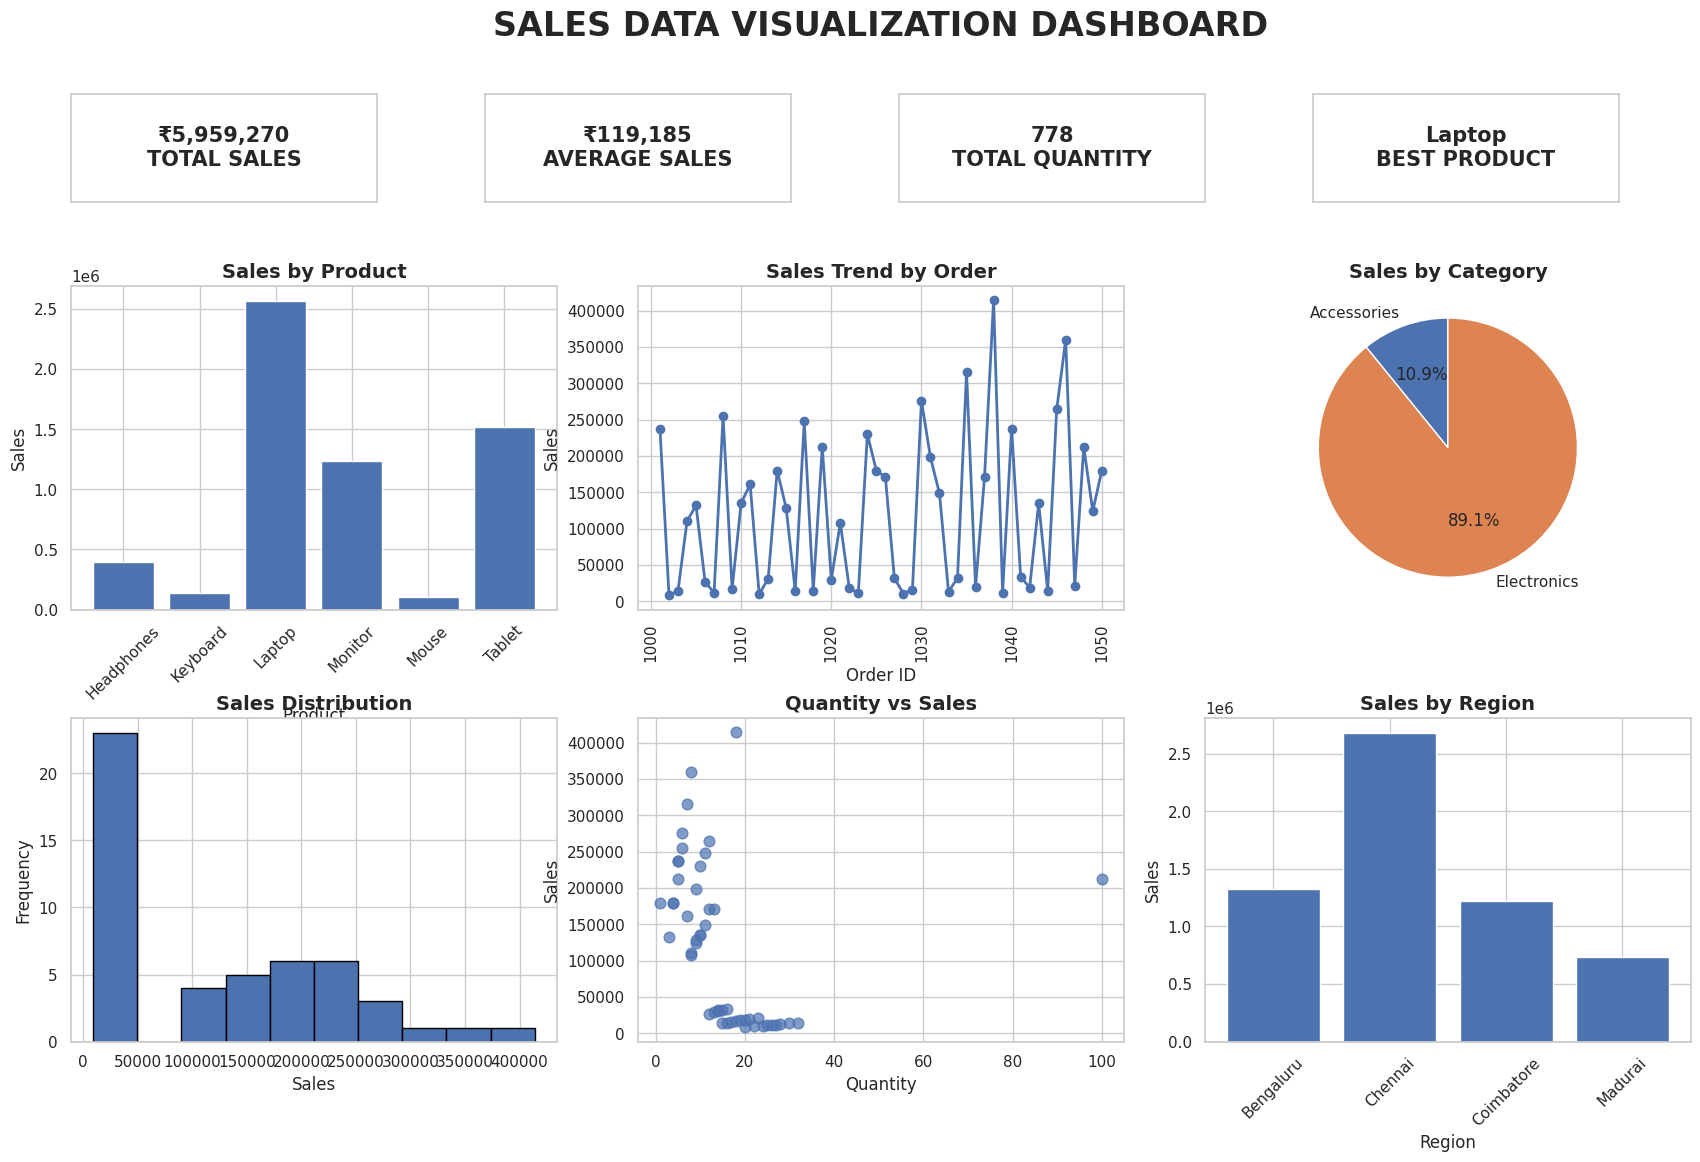


========== DASHBOARD INSIGHTS ==========
Total Sales: 5959270.0
Average Sales: 119185.4
Total Quantity Sold: 778
Best Selling Product: Laptop
Best Performing Region: Chennai
Best Performing Category: Electronics
Highest Sales: 414000.0
Lowest Sales: 9000.0

Dashboard successfully created.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("EDA_sales_dataset.csv")

print("Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

product_sales = df.groupby("Product")["Sales"].sum()
region_sales = df.groupby("Region")["Sales"].sum()
category_sales = df.groupby("Category")["Sales"].sum()

plt.figure(figsize=(8, 5))
plt.bar(product_sales.index, product_sales.values)
plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(df["Order_ID"], df["Sales"], marker="o")
plt.title("Sales Trend by Order")
plt.xlabel("Order ID")
plt.ylabel("Sales")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 7))
plt.pie(
    category_sales.values,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Sales Distribution by Category")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df["Sales"], bins=10, edgecolor="black")
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df["Quantity"], df["Sales"])
plt.title("Quantity vs Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(region_sales.index, region_sales.values)
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df["Unit_Price"], df["Sales"])
plt.title("Unit Price vs Sales")
plt.xlabel("Unit Price")
plt.ylabel("Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))

correlation = df[
    ["Quantity", "Unit_Price", "Discount",
     "Customer_Rating", "Sales"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

total_sales = df["Sales"].sum()
average_sales = df["Sales"].mean()
total_quantity = df["Quantity"].sum()

best_product = product_sales.idxmax()
best_region = region_sales.idxmax()
best_category = category_sales.idxmax()

sns.set_theme(style="whitegrid")

fig = plt.figure(figsize=(18, 12))

fig.suptitle(
    "SALES DATA VISUALIZATION DASHBOARD",
    fontsize=24,
    fontweight="bold",
    y=0.98
)

ax1 = fig.add_axes([0.05, 0.82, 0.17, 0.09])
ax2 = fig.add_axes([0.28, 0.82, 0.17, 0.09])
ax3 = fig.add_axes([0.51, 0.82, 0.17, 0.09])
ax4 = fig.add_axes([0.74, 0.82, 0.17, 0.09])

for ax in [ax1, ax2, ax3, ax4]:
    ax.set_xticks([])
    ax.set_yticks([])

ax1.text(
    0.5, 0.5,
    f"₹{total_sales:,.0f}\nTOTAL SALES",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

ax2.text(
    0.5, 0.5,
    f"₹{average_sales:,.0f}\nAVERAGE SALES",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

ax3.text(
    0.5, 0.5,
    f"{total_quantity}\nTOTAL QUANTITY",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

ax4.text(
    0.5, 0.5,
    f"{best_product}\nBEST PRODUCT",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

ax5 = fig.add_axes([0.05, 0.48, 0.27, 0.27])

ax5.bar(
    product_sales.index,
    product_sales.values
)

ax5.set_title(
    "Sales by Product",
    fontsize=14,
    fontweight="bold"
)

ax5.set_xlabel("Product")
ax5.set_ylabel("Sales")
ax5.tick_params(axis="x", rotation=45)

ax6 = fig.add_axes([0.365, 0.48, 0.27, 0.27])

ax6.plot(
    df["Order_ID"],
    df["Sales"],
    marker="o",
    linewidth=2
)

ax6.set_title(
    "Sales Trend by Order",
    fontsize=14,
    fontweight="bold"
)

ax6.set_xlabel("Order ID")
ax6.set_ylabel("Sales")
ax6.tick_params(axis="x", rotation=90)

ax7 = fig.add_axes([0.68, 0.48, 0.27, 0.27])

ax7.pie(
    category_sales.values,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

ax7.set_title(
    "Sales by Category",
    fontsize=14,
    fontweight="bold"
)

ax8 = fig.add_axes([0.05, 0.12, 0.27, 0.27])

ax8.hist(
    df["Sales"],
    bins=10,
    edgecolor="black"
)

ax8.set_title(
    "Sales Distribution",
    fontsize=14,
    fontweight="bold"
)

ax8.set_xlabel("Sales")
ax8.set_ylabel("Frequency")

ax9 = fig.add_axes([0.365, 0.12, 0.27, 0.27])

ax9.scatter(
    df["Quantity"],
    df["Sales"],
    s=60,
    alpha=0.7
)

ax9.set_title(
    "Quantity vs Sales",
    fontsize=14,
    fontweight="bold"
)

ax9.set_xlabel("Quantity")
ax9.set_ylabel("Sales")

ax10 = fig.add_axes([0.68, 0.12, 0.27, 0.27])

ax10.bar(
    region_sales.index,
    region_sales.values
)

ax10.set_title(
    "Sales by Region",
    fontsize=14,
    fontweight="bold"
)

ax10.set_xlabel("Region")
ax10.set_ylabel("Sales")
ax10.tick_params(axis="x", rotation=45)

plt.show()

print("\n========== DASHBOARD INSIGHTS ==========")
print("Total Sales:", total_sales)
print("Average Sales:", average_sales)
print("Total Quantity Sold:", total_quantity)
print("Best Selling Product:", best_product)
print("Best Performing Region:", best_region)
print("Best Performing Category:", best_category)
print("Highest Sales:", df["Sales"].max())
print("Lowest Sales:", df["Sales"].min())

print("\nDashboard successfully created.")